# 5 · From geodesic flows to robot motion

A distance field gives, at every configuration, the direction of the geodesic towards the
goal.  That is already a **policy**: no trajectory has to be optimised online, the robot just
follows the flow.  In this notebook we use it to generate *energy-efficient* motions for the
arm under gravity:

1. which metric makes "geodesic" mean "energy-efficient" (the Jacobi metric);
2. how a unit-speed geometric flow becomes a physical velocity;
3. a blended feedback policy and two low-level controllers (velocity / torque);
4. what the robot gains compared with a straight joint-space motion;
5. robustness to disturbances.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, rfm, nes, control as ct, plotting as P
from geodf.robots import PlanarArm

torch.manual_seed(0)
pi = np.pi
arm = PlanarArm()
lo, hi = [-pi, -pi], [pi, pi]
DT = 0.005                     # control / simulation step (s)

## 1. The Jacobi metric: geodesics are free motions

The arm now feels gravity, with potential energy $P(q)$, and the joint torques $\tau$ satisfy
$M\ddot q+C\dot q+g(q)=\tau$.  The power injected by the motors is $\dot H=\tau^\top\dot q$
(the time derivative of the total energy $H=T+P$).

* Any path can be followed at constant energy: move at the speed given by
  $\tfrac12\dot q^\top M\dot q=H-P(q)$ and use only torques orthogonal to the velocity, which do no
  work but are needed to bend the free motion onto the path.
* By Maupertuis' principle, the paths of the **free** motion ($\tau=0$) with energy $H$ are
  the geodesics of the Jacobi metric (notebook 4)
  $$G(q)=2\big(H-P(q)\big)\,M(q).$$
  Following a geodesic at the energy-$H$ speed therefore needs **no torque at all**.

So the closer a motion is to a Jacobi geodesic, the less torque it needs.  We use
$H=1.2\,P_{max}$, a low energy level just above the highest potential.

In [2]:
H = 1.2 * arm.P_max
G = metrics.jacobi(arm, H)
print(f"P_max = {arm.P_max:.1f} J,  H = {H:.1f} J")

model = nes.NES(lo, hi, hidden=(128, 128, 128))
nes.train_or_load(model, "checkpoints/nes_jacobi_1.2.pt", lambda: nes.train(
    model, nes.uniform_pair_sampler(lo, hi, 1024), lambda q, w: torch.linalg.inv(G(q)), steps=15000, log_every=3000),
    retrain=False)
model.eval();

P_max = 58.9 J,  H = 70.6 J
loaded checkpoints/nes_jacobi_1.2.pt (trained in 121s)


## 2. From a unit-speed flow to a physical velocity

The geodesic flow $V=G^{-1}\nabla U$ has unit speed in the metric, $V^\top G V=1$.  A motion
at energy $H$ must have kinetic energy $\tfrac12\dot q^\top M\dot q=H-P(q)$.  Plugging in
$G=2(H-P)M$ gives the scaling

$$\dot q = 2\big(H-P(q)\big)\,V(q):$$

the arm moves fast where the potential is low and slows down where it is high, like a
pendulum.  (`metrics.jacobi_speed` returns this factor.)

In [3]:
SPEED = metrics.jacobi_speed(arm, H)
q_goal = np.array([1.5, 1.0])
q_start = np.array([-2.0, -1.0])
q = torch.tensor(q_start[None], dtype=torch.float32)
U, V = nes.geodesic_flow(model, torch.tensor(q_goal[None], dtype=torch.float32), q, G)
qd = (SPEED(q)[:, None] * V)[0].numpy()
M = arm.inertia(q.double())[0].numpy()
print(f"distance to the goal U = {U.item():.1f}")
print(f"geodesic direction -V = {(-V[0]).numpy().round(4)}  (unit G-speed: V^T G V = "
      f"{(V @ G(q)[0] @ V.T).item():.3f})")
print(f"physical velocity = {(-qd).round(3)} rad/s,  kinetic energy {0.5 * qd @ M @ qd:.1f} J  "
      f"=  H - P(q) = {H - arm.potential(q.double()).item():.1f} J")

distance to the goal U = 155.1
geodesic direction -V = [ 0.025  -0.0473]  (unit G-speed: V^T G V = 1.000)
physical velocity = [  5.459 -10.316] rad/s,  kinetic energy 109.1 J  =  H - P(q) = 109.1 J


### Seeing Maupertuis' principle

Before adding controllers, let us check the claim of section 1 directly.  We take two paths
from `q_start` to `q_goal` — a Jacobi geodesic (from the grid solver of notebook 2) and the
straight line — and traverse each at the energy-$H$ speed.  Inverse dynamics then gives the
torque needed to move the arm exactly like this (gravity included).

Jacobi geodesic  total energy 70.63 .. 70.63 J (H = 70.63)   median |tau|  0.85 N m   max |power| 0.15 W
straight line    total energy 70.63 .. 70.63 J (H = 70.63)   median |tau|  4.33 N m   max |power| 0.00 W


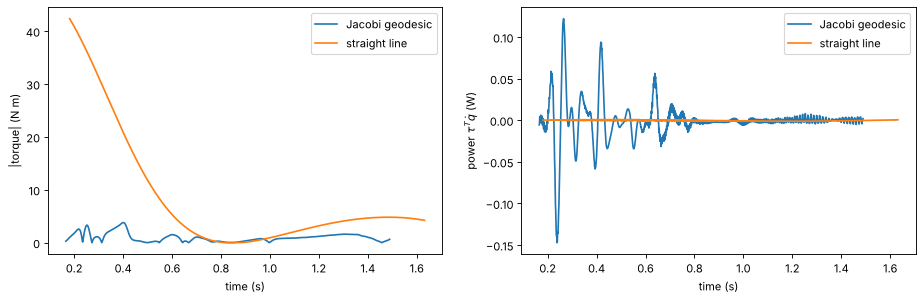

In [4]:
from scipy.interpolate import make_smoothing_spline

G64 = lambda q: G(q.double())
geo = rfm.solve(G64, ((-pi, pi), (-pi, pi)), 300, q_goal).backtrack(q_start, step=0.3)[:-1]
line = np.linspace(q_start, q_goal, 400)


def traverse_at_energy_H(path, n=1500):
    """Time-parameterise a path so that 1/2 qd^T M qd = H - P, and compute the torques."""
    p = torch.as_tensor(path, dtype=torch.float64)
    mid, d = 0.5 * (p[1:] + p[:-1]), p[1:] - p[:-1]
    ds_M = torch.sqrt(torch.einsum("ni,nij,nj->n", d, arm.inertia(mid), d))
    speed_M = torch.sqrt(2 * (H - arm.potential(mid)))            # |qd|_M at energy H
    t = np.concatenate([[0], np.cumsum((ds_M / speed_M).numpy())])
    tt = np.linspace(0, t[-1], n)
    sp = [make_smoothing_spline(t, path[:, i], lam=1e-6) for i in range(2)]
    q, qd, qdd = [torch.as_tensor(np.stack([s.derivative(k)(tt) if k else s(tt) for s in sp], 1)) for k in range(3)]
    tau = arm.inverse_dynamics(q, qd, qdd, gravity=True).numpy()
    E = (0.5 * torch.einsum("ni,nij,nj->n", qd, arm.inertia(q), qd) + arm.potential(q)).numpy()
    inner = slice(n // 10, -n // 10)                               # ignore spline end effects
    return tt[inner], tau[inner], (tau * qd.numpy()).sum(1)[inner], E[inner]


fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for name, path, c in [("Jacobi geodesic", geo, "tab:blue"), ("straight line", line, "tab:orange")]:
    t, tau, power, E = traverse_at_energy_H(path)
    print(f"{name:16s} total energy {E.min():.2f} .. {E.max():.2f} J (H = {H:.2f})   "
          f"median |tau| {np.median(np.linalg.norm(tau, axis=1)):5.2f} N m   max |power| {np.abs(power).max():.2f} W")
    axs[0].plot(t, np.linalg.norm(tau, axis=1), color=c, label=name)
    axs[1].plot(t, power, color=c, label=name)
axs[0].set_xlabel("time (s)"); axs[0].set_ylabel("|torque| (N m)"); axs[0].legend()
axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("power $\\tau^T\\dot q$ (W)"); axs[1].legend()
plt.show()

Both motions keep the total energy exactly at $H$, and in both the motors do no work (power
≈ 0).  But the straight line needs large torques all along — workless torques that bend the
arm's free motion onto the line — while along the geodesic the torque is essentially zero
(what remains comes from the discretised path): **the geodesic is the motion the arm makes by
itself**.  This is why geodesics of the Jacobi metric are energy-efficient.

## 3. A feedback policy and low-level control

Following $-V$ exactly becomes numerically delicate very close to the goal (the flow is
singular there).  The policy therefore blends the geodesic flow with a simple attraction
$q_g-q$, with a weight that depends on the remaining distance $U$:

$$\dot q_{des}(q)=-\lambda(q)\,\dot q_{geo}(q)+\big(1-\lambda(q)\big)(q_g-q),\qquad
  \lambda(q)=\frac{\beta U(q)}{1+\beta U(q)},$$

where $\dot q_{geo}=2(H-P)V$ is the flow at the physical speed (section 2; the minus sign points
towards the goal).

Far from the goal $\lambda\approx1$ (pure geodesic flow); near the goal $\lambda\to0$.

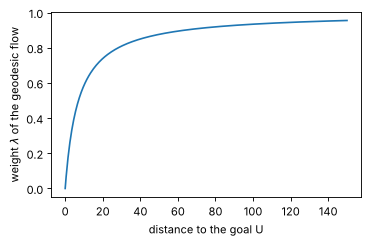

In [5]:
BETA = 20.0 / (2 * H)          # U is measured in units of action, ~2H per unit of time
u = np.linspace(0, 150, 300)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(u, BETA * u / (1 + BETA * u))
ax.set_xlabel("distance to the goal U"); ax.set_ylabel("weight $\\lambda$ of the geodesic flow")
plt.show()


def nes_policy(goal):
    g = torch.as_tensor(goal, dtype=torch.float32)[None]

    def policy(q):
        qt = torch.as_tensor(q, dtype=torch.float32)[None]
        U, V = nes.geodesic_flow(model, g, qt, G)
        v = (V * SPEED(qt)[:, None]).double().numpy()        # physical velocity along the geodesic
        return ct.blended_velocity(U.double().numpy(), v, q[None], goal[None], BETA)[0]
    return policy

The desired velocity is handed to a low-level controller that enforces the robot's limits.

* **Velocity level** (`control.rollout_velocity`): a small QP finds the joint velocity closest
  to $\dot q_{des}$ that respects joint-position, velocity (5 rad/s) and acceleration
  (20 rad/s²) limits.  The robot starts at rest.
* **Torque level** (`control.rollout_torque`): a QP finds torques that track $\dot q_{des}$
  through the full dynamics $M\ddot q+C\dot q+g=\tau$ (with gravity), and the arm is simulated
  forward.

At this energy the free motion would be fast (about 10 rad/s here), so the velocity limit is
active in the middle of the motion: the controllers follow the geodesic *direction* and slow
down where needed.  Torques are computed for both controllers (by inverse dynamics for the
velocity-level motion).

In [6]:
traj_vel = ct.rollout_velocity(nes_policy(q_goal), q_start, q_goal, dt=DT)
traj_tau, taus = ct.rollout_torque(arm, nes_policy(q_goal), q_start, q_goal, dt=DT)
print(f"velocity control: reached the goal in {len(traj_vel) * DT:.2f} s")
print(f"torque control:   reached the goal in {len(traj_tau) * DT:.2f} s")

velocity control: reached the goal in 2.89 s
torque control:   reached the goal in 2.72 s


## 4. What the geodesic buys: comparison with a straight joint-space motion

As a reference we execute the straight line from start to goal with the **same** controller and
the same speed rule (`control.path_policy` follows a given path at the energy-$H$ speed).  We
measure the length of each motion in the Jacobi metric and two torque costs:

* L2 torque $\sqrt{\int\tau^\top\tau\,dt}$ — total control effort;
* active torque $\sqrt{\int(\tau^\top\dot q)^2dt}$ — torque that does mechanical work, i.e.
  changes the energy of the arm.

In [7]:
traj_line = ct.rollout_velocity(ct.path_policy(line, G64, q_goal, beta=BETA, speed=SPEED), q_start, q_goal, dt=DT)

rows = {"NES, velocity control": ct.evaluate(arm, G64, traj_vel, DT),
        "NES, torque control": ct.evaluate(arm, G64, traj_tau, DT, taus),
        "straight line, velocity control": ct.evaluate(arm, G64, traj_line, DT)}
print(f"{'':34s}{'Jacobi length':>14s}{'L2 torque':>11s}{'active torque':>15s}{'duration':>10s}")
for k, r in rows.items():
    print(f"{k:34s}{r['length']:14.1f}{r['l2_torque']:11.1f}{r['active_torque']:15.1f}{r['duration']:9.2f}s")

                                   Jacobi length  L2 torque  active torque  duration
NES, velocity control                      158.7       86.9          223.8     2.89s
NES, torque control                        158.3       76.5          182.7     2.72s
straight line, velocity control            219.8      160.6          319.6     2.42s


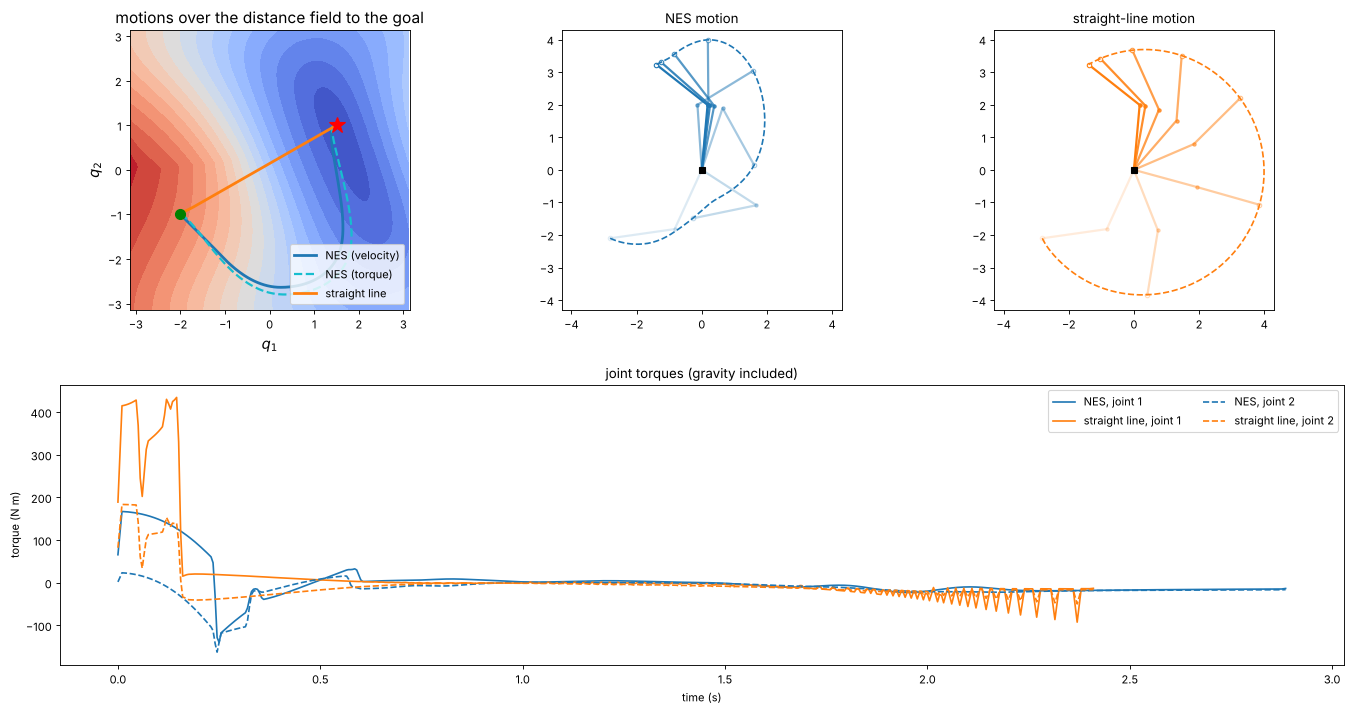

In [8]:
sol = rfm.solve(G64, ((-pi, pi), (-pi, pi)), 150, q_goal)     # only for the background picture
tau_vel, _ = ct.finite_diff_torque(arm, traj_vel, DT)
tau_line, _ = ct.finite_diff_torque(arm, traj_line, DT)

fig = plt.figure(figsize=(17, 9))
ax = fig.add_subplot(2, 3, 1)
P.field(ax, sol.grid.X, sol.grid.Y, sol.U, lines=False)
ax.plot(*traj_vel.T, color="tab:blue", lw=2.5, label="NES (velocity)")
ax.plot(*traj_tau.T, "--", color="tab:cyan", lw=2, label="NES (torque)")
ax.plot(*traj_line.T, color="tab:orange", lw=2.5, label="straight line")
ax.plot(*q_start, "go", ms=9); ax.plot(*q_goal, "r*", ms=15)
ax.legend(loc="lower right")
P.setup_ax(ax, title="motions over the distance field to the goal")
ax = fig.add_subplot(2, 3, 2)
P.arm_motion(ax, arm, traj_vel, "tab:blue", n=8)
ax.set_title("NES motion")
ax = fig.add_subplot(2, 3, 3)
P.arm_motion(ax, arm, traj_line, "tab:orange", n=8)
ax.set_title("straight-line motion")
ax = fig.add_subplot(2, 1, 2)
t1, t2 = np.arange(len(tau_vel)) * DT, np.arange(len(tau_line)) * DT
for j, ls in [(0, "-"), (1, "--")]:
    ax.plot(t1, tau_vel[:, j], ls, color="tab:blue", label=f"NES, joint {j + 1}")
    ax.plot(t2, tau_line[:, j], ls, color="tab:orange", label=f"straight line, joint {j + 1}")
ax.set_xlabel("time (s)"); ax.set_ylabel("torque (N m)"); ax.legend(ncol=2)
ax.set_title("joint torques (gravity included)")
plt.tight_layout()
plt.show()

The geodesic motion keeps the elbow folded ($q_2\approx-2.4$) while it swings the shoulder,
which makes the arm light, and opens the elbow at the end.  Its Jacobi length is shorter and it
needs about half the torque of the straight joint-space motion executed with the same controller.

Why not zero torque?  An ideal geodesic followed at the energy-$H$ speed would be a free motion.
Here the robot starts and stops at rest (the large torques at the beginning), the velocity limit
of 5 rad/s is below the free speed (~10 rad/s at the start), and the policy blends towards the
goal at the end — all of which require torque.  The straight line additionally needs torque all
along to keep the motion on a path that is not a free motion.

## 5. Robustness: the policy is global

Because the policy is defined everywhere, a disturbance needs no re-planning: after a push the
robot simply follows the flow from wherever it ended up.  Below, the arm is pushed by 1 rad on
joint 2 after 0.5 s.

reached the goal 2.91 s after the start (final error 0.020 rad)


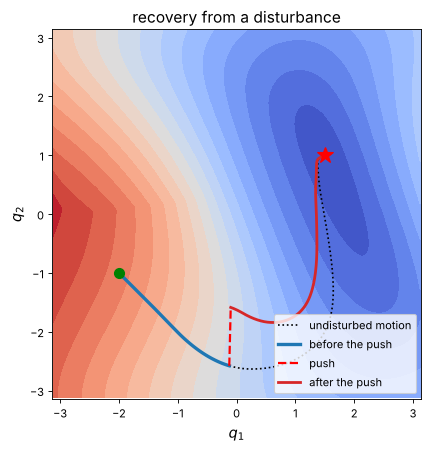

In [9]:
pol = nes_policy(q_goal)
q, qd, traj, pushed = q_start.copy(), np.zeros(2), [q_start.copy()], None
for k in range(int(6 / DT)):
    if np.linalg.norm(q - q_goal) < 0.02:
        break
    if k == int(0.5 / DT):
        q = q + np.array([0.0, 1.0]); pushed = len(traj)
    qd = ct.kinematic_qp(pol(q), q, DT, ct.QD_LIM, -pi, pi, qd, ct.QDD_LIM)
    q = q + DT * qd
    traj.append(q.copy())
traj = np.array(traj)
print(f"reached the goal {len(traj) * DT:.2f} s after the start (final error {np.linalg.norm(traj[-1] - q_goal):.3f} rad)")

fig, ax = plt.subplots(figsize=(6, 6))
P.field(ax, sol.grid.X, sol.grid.Y, sol.U, lines=False)
ax.plot(*traj_vel.T, ":", color="k", lw=1.5, label="undisturbed motion")
ax.plot(*traj[:pushed].T, color="tab:blue", lw=3, label="before the push")
ax.plot(*traj[pushed - 1:pushed + 1].T, "r--", lw=2, label="push")
ax.plot(*traj[pushed:].T, color="tab:red", lw=2.5, label="after the push")
ax.plot(*q_start, "go", ms=9); ax.plot(*q_goal, "r*", ms=15)
ax.legend(loc="lower right")
P.setup_ax(ax, title="recovery from a disturbance")
plt.show()